# EN3160 Assignment 2 — Fitting and Alignment

**Name:** Heshan Ranasinghe  
**Index:** 230521E  
**GitHub profile:** https://github.com/DPHeshanRanasinghe/EN3160-Image-Processing-and-Machine-Vision

In [3]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_DIR = Path("images")

if not IMAGE_DIR.is_dir():
    IMAGE_DIR = Path("Assignment_02") / "images"

if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(
        f"Cannot find the Assignment_02 images folder.\n"
        f"Current working folder: {Path.cwd()}"
    )

required_images = [
    "the_berry_farms_sunflower_field.jpeg",
    "wadham.jpg",
    "flag.png",
    "pcbs/AAAA1.jpg",
    "pcbs/ADAD1.jpg",
    "pcbs/AECC1.jpg",
    "pcbs/AECC2.jpg",
    "pcbs/AECC3.jpg",
    "pcbs/AECC4.jpg",
]


missing = [
    name for name in required_images
    if not (IMAGE_DIR / name).is_file()
]

if missing:
    raise FileNotFoundError(f"Missing images: {missing}")

print("Image folder:", IMAGE_DIR.resolve())
print("All required images are available.")

Image folder: D:\3_Semester 5\Image Processing & Machine Vision\github\Assignment_02\images
All required images are available.


## Question 1 — Sunflower candidates using LoG

I loaded the supplied image with `cv2.IMREAD_REDUCED_COLOR_4`, reducing it from 1440 × 1440 to 360 × 360 pixels. I detect dark flower-centre candidates using the positive, scale-normalized response `sigma**2 * gaussian_laplace(gray, sigma)`, then select maxima in a 3 × 3 × 3 neighbourhood across scale, row and column. I also verify yellow petals around each peak and reject strongly green centres. This extra colour check uses the whole image; I do not insert circles or specify flower locations. I compare this result with the original absolute-response detector and with signed LoG alone. All coordinates and sizes refer to the reduced image: **x = row, y = column**, while plotted circle centres are `(column, row)`.

The middle and right panels use the same revised scales, size limits and duplicate rule, so they show the effect of colour verification. The original panel keeps the original settings.


Reduced image: 360 x 360 pixels; all measurements below use it.
Computed sigma range: 1-32 px (41 geometric samples, ratio 1.0905).
Eligible sigma: radius >= 2.5 px and sigma <= 20 px; endpoints are guards.
Original absolute LoG: t=0.08 -> 187; t=0.12 -> 135 candidates.
Signed LoG alone: 298; with petal check: t=0.08 -> 56, t=0.12 -> 54 candidates.
Retained sigma range: 1.834-7.336 px.


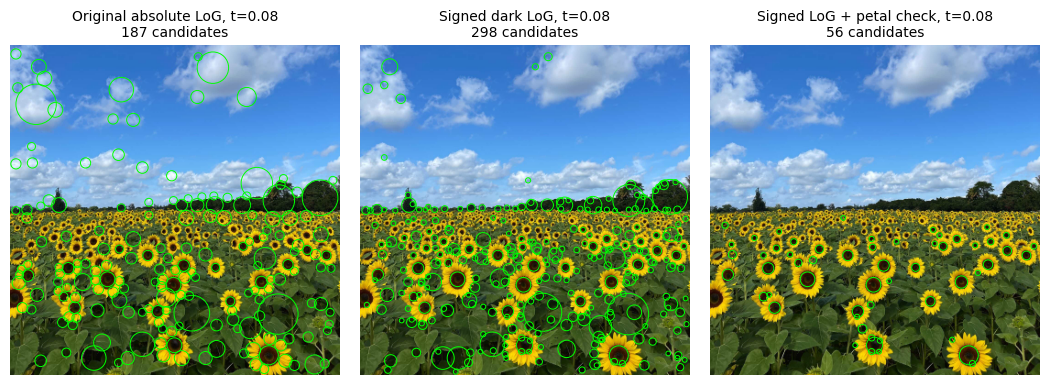

**Largest retained flower-centre candidates**

| x = row | y = column | sigma (px) | radius (px) | LoG response |
|---:|---:|---:|---:|---:|
| 338 | 282 | 7.336 | 10.375 | 0.3491 |
| 327 | 179 | 6.169 | 8.724 | 0.3447 |
| 255 | 106 | 5.657 | 8.000 | 0.3617 |
| 261 | 178 | 5.657 | 8.000 | 0.3527 |
| 258 | 274 | 4.757 | 6.727 | 0.3448 |


In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.ndimage import gaussian_laplace, maximum_filter
from IPython.display import display, Markdown

q1_path = Path('images/the_berry_farms_sunflower_field.jpeg')
if not q1_path.is_file():
    q1_path = Path('Assignment_02') / q1_path
q1_bgr = cv2.imread(str(q1_path), cv2.IMREAD_REDUCED_COLOR_4)
if q1_bgr is None:
    raise FileNotFoundError(q1_path)
q1_rgb = cv2.cvtColor(q1_bgr, cv2.COLOR_BGR2RGB)
q1_gray = cv2.cvtColor(q1_bgr, cv2.COLOR_BGR2GRAY).astype(float) / 255
q1_colour = q1_rgb.astype(float) / 255
q1_yellow = np.maximum(np.minimum(q1_colour[..., 0], q1_colour[..., 1])
                       - q1_colour[..., 2], 0)
q1_height, q1_width = q1_gray.shape

# Eight samples per octave; the endpoints are guard scales, not detections.
q1_sigmas = np.geomspace(1, 32, 41)
q1_response = np.stack([
    s**2 * gaussian_laplace(q1_gray, s, mode='reflect') for s in q1_sigmas
])  # Positive LoG selects dark centres; negative LoG selects bright blobs.

def q1_peak_indices(response, threshold, strict_scale=True):
    # Explicit 26-neighbour comparison in (scale, row, column).
    peaks = response == maximum_filter(response, size=(3, 3, 3),
                                       mode='constant', cval=-np.inf)
    peaks[[0, -1]] = False
    if strict_scale:  # Reject flat scale plateaus rather than duplicating them.
        peaks[1:-1] &= ((response[1:-1] > response[:-2]) &
                       (response[1:-1] > response[2:]))
    indices = np.argwhere(peaks & (response > threshold))
    order = np.argsort(-response[tuple(indices.T)], kind='stable')
    return indices[order]

def q1_petal_check(row, col, radius):
    # Verify colour around a LoG peak; do not generate or move its centre.
    a, b = max(0, int(row-2*radius)), min(q1_height, int(row+2*radius)+1)
    c, d = max(0, int(col-2*radius)), min(q1_width, int(col+2*radius)+1)
    rr, cc = np.ogrid[a:b, c:d]
    dr, dc = rr-row, cc-col
    distance = np.hypot(dr, dc)
    core = distance <= 0.65*radius
    ring = (distance >= 1.05*radius) & (distance <= 1.9*radius)
    yellow = q1_yellow[a:b, c:d]
    rgb = q1_colour[a:b, c:d]
    # Yellow must surround several sides, not just one neighbouring flower.
    sectors = np.floor((np.arctan2(dr, dc)+np.pi)*4/np.pi).astype(int) % 8
    supported = 0
    for sector in range(8):
        pixels = ring & (sectors == sector)
        supported += pixels.any() and np.mean(yellow[pixels] > 0.22) >= 0.15
    return (np.mean(yellow[ring] > 0.22) >= 0.30
            and yellow[ring].mean()-yellow[core].mean() >= 0.08
            and (rgb[..., 0][core].mean()-rgb[..., 1][core].mean()) >= -0.04
            and supported >= 5)

def q1_select(response, sigmas, threshold, verify=False, old_rule=False):
    selected = []
    for k, row, col in q1_peak_indices(response, threshold,
                                      strict_scale=not old_rule):
        sigma = sigmas[k]
        radius = np.sqrt(2)*sigma
        if radius < (4 if old_rule else 2.5):
            continue
        if not old_rule and sigma > 20:  # Larger computed scales are guards.
            continue
        if not (radius <= row < q1_height-radius and
                radius <= col < q1_width-radius):
            continue  # Incomplete dark disks are not reported.
        if verify and not q1_petal_check(row, col, radius):
            continue  # Reject background before it can suppress a flower.
        duplicate = any(
            np.hypot(row-v[0], col-v[1]) <
            (0.7*(radius+v[3]) if old_rule else 0.6*min(radius, v[3]))
            for v in selected
        )
        if not duplicate:
            selected.append((row, col, sigma, radius, response[k, row, col]))
    return np.asarray(selected, dtype=float).reshape(-1, 5)

# Reproduce the original method so the comparison uses the same image.
q1_original_sigmas = np.geomspace(1, 20, 25)
q1_original_response = np.stack([
    s**2 * np.abs(gaussian_laplace(q1_gray, s, mode='reflect'))
    for s in q1_original_sigmas
])
q1_original = {t: q1_select(q1_original_response, q1_original_sigmas, t,
                           old_rule=True) for t in (0.08, 0.12)}
q1_dark_only = q1_select(q1_response, q1_sigmas, 0.08)
q1_final = q1_select(q1_response, q1_sigmas, 0.08, verify=True)
q1_final_high = q1_select(q1_response, q1_sigmas, 0.12, verify=True)

print(f'Reduced image: {q1_width} x {q1_height} pixels; all measurements below use it.')
print('Computed sigma range: 1-32 px (41 geometric samples, ratio 1.0905).')
print('Eligible sigma: radius >= 2.5 px and sigma <= 20 px; endpoints are guards.')
print(f'Original absolute LoG: t=0.08 -> {len(q1_original[0.08])}; '
      f't=0.12 -> {len(q1_original[0.12])} candidates.')
print(f'Signed LoG alone: {len(q1_dark_only)}; with petal check: '
      f't=0.08 -> {len(q1_final)}, t=0.12 -> {len(q1_final_high)} candidates.')
if len(q1_final):
    print(f'Retained sigma range: {q1_final[:, 2].min():.3f}-'
          f'{q1_final[:, 2].max():.3f} px.')

q1_fig, q1_axes = plt.subplots(1, 3, figsize=(10.5, 3.7),
                               constrained_layout=True)
q1_panels = [('Original absolute LoG, t=0.08', q1_original[0.08]),
             ('Signed dark LoG, t=0.08', q1_dark_only),
             ('Signed LoG + petal check, t=0.08', q1_final)]
for ax, (title, candidates) in zip(q1_axes, q1_panels):
    ax.imshow(q1_rgb)
    for row, col, sigma, radius, score in candidates:
        ax.add_patch(Circle((col, row), radius, fill=False,
                            edgecolor='lime', linewidth=0.7))
    ax.set_title(f'{title}\n{len(candidates)} candidates', fontsize=10)
    ax.axis('off')
plt.show()

# Largest by radius, with response strength as a deterministic tie-breaker.
q1_largest = q1_final[np.lexsort((-q1_final[:, 4], -q1_final[:, 3]))][:5]
q1_table = '| x = row | y = column | sigma (px) | radius (px) | LoG response |\n'
q1_table += '|---:|---:|---:|---:|---:|\n'
for row, col, sigma, radius, score in q1_largest:
    q1_table += f'| {row:.0f} | {col:.0f} | {sigma:.3f} | {radius:.3f} | {score:.4f} |\n'
display(Markdown('**Largest retained flower-centre candidates**\n\n'+q1_table))


### Interpretation and discussion

The original absolute-LoG detector produced 187 candidates at threshold 0.08, including clouds, trees and leaves. The revised signed-LoG detector still produced 298 candidates, showing that intensity patterns alone could not reliably distinguish flowers from the background.

I therefore added a colour check for yellow petals surrounding each dark-centre candidate. This reduced the result to 56 candidates and visibly removed many background detections. I evaluated 41 sigma values from 1–32 pixels, including guard scales, and accepted radii of at least 2.5 pixels with sigma no greater than 20 pixels.

I selected threshold 0.08 because thresholds 0.08 and 0.10 both retained 56 candidates, while 0.12 retained 54. The retained sigma range was 1.834–7.336 pixels, giving a largest estimated radius of 10.375 pixels.

The circles describe dark flower centres rather than complete petal boundaries. Some distant, tilted, overlapping or shaded flowers are missed, and some small candidates remain uncertain. The count is therefore a candidate count, not a verified number of sunflowers.